# 06. A/B Testing & Funnel Experimentation: 1-Click Guest Checkout

## Business Context & Experiment Motivation
In the preceding funnel analysis (`03_customer_funnel_analysis.ipynb`), we identified that **61.6% of users who added items to their shopping cart dropped off before completing checkout**. User session diagnostics indicated that mandatory registration and multi-page form friction were the primary abandonment drivers.

To test this bottleneck, Product & Analytics designed a randomized controlled experiment:
* **Control Group (A):** Standard 3-Step Checkout (Account creation required, shipping form, payment review).
* **Treatment Group (B):** 1-Click Guest Checkout (Streamlined single-page checkout with express payment options).

## Experiment Hypothesis & Metric Taxonomy
* **Primary Metric (OEC):** Cart-to-Order Conversion Rate ($\text{Orders} / \text{Cart Sessions}$).
* **Hypothesis ($H_1$):** Variant B will deliver at least a **5.0% relative conversion lift** over the baseline ($p < 0.05$).
* **Null Hypothesis ($H_0$):** There is no difference in conversion rates between Control and Treatment ($p_B - p_A = 0$).
* **Guardrail Metric:** Average Order Value (AOV). Must show no statistically significant dilution (Two-Sample T-Test $p > 0.05$).
* **Minimum Detectable Effect (MDE):** 5% relative uplift (from 38.4% baseline to ~40.3%).
* **Statistical Power ($1 - \beta$):** 80%.
* **Significance Level ($\alpha$):** 5% ($Z_{0.025} = 1.96$).


In [1]:
import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportions_ztest, proportion_effectsize, confint_proportions_2indep
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

print("Analytics & Statistical libraries loaded successfully.")


Analytics & Statistical libraries loaded successfully.


In [2]:
# Pre-Experiment Power Analysis & Sample Size Determination
baseline_cr = 0.3840
mde_relative = 0.05  # 5% relative uplift
target_cr = baseline_cr * (1 + mde_relative)

alpha = 0.05
power = 0.80

effect_size = proportion_effectsize(baseline_cr, target_cr)

power_analysis = NormalIndPower()
required_n_per_variant = int(np.ceil(power_analysis.solve_power(
    effect_size=effect_size,
    power=power,
    alpha=alpha,
    ratio=1.0
)))

total_required_sample = required_n_per_variant * 2

print("=== PRE-EXPERIMENT POWER ANALYSIS ===")
print(f"Baseline Conversion Rate:  {baseline_cr * 100:.2f}%")
print(f"Target Conversion Rate:    {target_cr * 100:.2f}% (MDE: +{mde_relative * 100:.1f}%)")
print(f"Significance Level (alpha): {alpha}")
print(f"Statistical Power (1-beta): {power}")
print(f"Required Sample per Group:  {required_n_per_variant:,} visitors")
print(f"Total Experiment Size:      {total_required_sample:,} visitors")


=== PRE-EXPERIMENT POWER ANALYSIS ===
Baseline Conversion Rate:  38.40%
Target Conversion Rate:    40.32% (MDE: +5.0%)
Significance Level (alpha): 0.05
Statistical Power (1-beta): 0.8
Required Sample per Group:  10,163 visitors
Total Experiment Size:      20,326 visitors


In [3]:
# Load Experiment Telemetry
df_ab = pd.read_csv("data/ab_test_traffic_log.csv")

print(f"Total Logged Visitors: {len(df_ab):,}")
print("\nSample Records:")
display(df_ab.head())

# Group-level Aggregation
summary_table = df_ab.groupby("variant").agg(
    visitors=("user_id", "count"),
    conversions=("converted", "sum"),
    total_gmv=("order_amount", "sum")
).reset_index()

summary_table["conversion_rate"] = summary_table["conversions"] / summary_table["visitors"]
summary_table["aov"] = summary_table["total_gmv"] / summary_table["conversions"]

print("\nExperiment Summary:")
display(summary_table)


Total Logged Visitors: 21,000

Sample Records:


,user_id,variant,day,device,converted,order_amount
0,USR-CTL-00026,Control,1,Mobile,1,14.51
1,USR-CTL-00030,Control,1,Desktop,0,0.00
2,USR-CTL-00040,Control,1,Desktop,0,0.00
3,USR-CTL-00069,Control,1,Desktop,0,0.00
4,USR-CTL-00074,Control,1,Mobile,1,39.22



Experiment Summary:

,variant,visitors,conversions,total_gmv,conversion_rate,aov
0,Control,10520,3931,186589.11,0.373669,47.466067
1,Treatment,10480,4391,207207.37,0.418989,47.189107


In [4]:
# Sample Ratio Mismatch (SRM) Test
observed_counts = summary_table["visitors"].values
expected_counts = [len(df_ab) / 2, len(df_ab) / 2]

chi2_stat, srm_p_value = stats.chisquare(observed_counts, f_exp=expected_counts)

print("=== SAMPLE RATIO MISMATCH (SRM) DIAGNOSTIC ===")
print(f"Observed Counts (Control vs Treatment): {observed_counts[0]:,} vs {observed_counts[1]:,}")
print(f"Expected 50/50 Split:                   {expected_counts[0]:,.0f} vs {expected_counts[1]:,.0f}")
print(f"Chi-Square Test Statistic:              {chi2_stat:.4f}")
print(f"P-Value:                                {srm_p_value:.4f}")

if srm_p_value > 0.05:
    print("CONCLUSION: No Sample Ratio Mismatch detected. Traffic split is clean and unbiased (p > 0.05).")
else:
    print("WARNING: Sample Ratio Mismatch detected! Telemetry or routing bias must be investigated.")


=== SAMPLE RATIO MISMATCH (SRM) DIAGNOSTIC ===
Observed Counts (Control vs Treatment): 10,520 vs 10,480
Expected 50/50 Split:                   10,500 vs 10,500
Chi-Square Test Statistic:              0.0762
P-Value:                                0.7825
CONCLUSION: No Sample Ratio Mismatch detected. Traffic split is clean and unbiased (p > 0.05).


In [5]:
# Hypothesis Testing: Two-Proportion Z-Test
conversions = [
    summary_table.loc[summary_table["variant"]=="Treatment", "conversions"].values[0],
    summary_table.loc[summary_table["variant"]=="Control", "conversions"].values[0]
]
visitors = [
    summary_table.loc[summary_table["variant"]=="Treatment", "visitors"].values[0],
    summary_table.loc[summary_table["variant"]=="Control", "visitors"].values[0]
]

z_score, p_value = proportions_ztest(conversions, visitors, alternative="two-sided")

cr_control = conversions[1] / visitors[1]
cr_treatment = conversions[0] / visitors[0]
abs_diff = cr_treatment - cr_control
rel_lift = (cr_treatment - cr_control) / cr_control * 100

# 95% Confidence Interval for Difference in Proportions
ci_lower, ci_upper = confint_proportions_2indep(
    conversions[0], visitors[0], conversions[1], visitors[1], method="wald", alpha=0.05
)

print("=== STATISTICAL HYPOTHESIS TESTING ===")
print(f"Control Conversion Rate:   {cr_control * 100:.2f}%")
print(f"Treatment Conversion Rate: {cr_treatment * 100:.2f}%")
print(f"Absolute Difference:       {abs_diff * 100:+.2f}%")
print(f"Relative Conversion Lift:  {rel_lift:+.2f}%")
print(f"Z-Score:                   {z_score:.4f}")
print(f"P-Value:                   {p_value:.6f}")
print(f"95% Confidence Interval:   [{ci_lower * 100:.2f}%, {ci_upper * 100:.2f}%]")

if p_value < 0.05 and ci_lower > 0:
    print("\nDECISION: REJECT NULL HYPOTHESIS (H0). The 1-Click Guest Checkout delivers a statistically significant conversion lift.")
else:
    print("\nDECISION: FAIL TO REJECT NULL HYPOTHESIS (H0).")


=== STATISTICAL HYPOTHESIS TESTING ===
Control Conversion Rate:   37.37%
Treatment Conversion Rate: 41.90%
Absolute Difference:       +4.53%
Relative Conversion Lift:  +12.13%
Z-Score:                   6.7134
P-Value:                   0.000000
95% Confidence Interval:   [3.21%, 5.85%]

DECISION: REJECT NULL HYPOTHESIS (H0). The 1-Click Guest Checkout delivers a statistically significant conversion lift.


In [6]:
# Guardrail Metric Validation: Two-Sample T-Test on Order Amount
order_val_ctl = df_ab[(df_ab["variant"]=="Control") & (df_ab["converted"]==1)]["order_amount"]
order_val_trt = df_ab[(df_ab["variant"]=="Treatment") & (df_ab["converted"]==1)]["order_amount"]

t_stat, p_val_aov = stats.ttest_ind(order_val_ctl, order_val_trt, equal_var=False)

print("=== GUARDRAIL METRIC: AVERAGE ORDER VALUE (AOV) ===")
print(f"Control Mean AOV:    ${order_val_ctl.mean():.2f} (Std: ${order_val_ctl.std():.2f})")
print(f"Treatment Mean AOV:  ${order_val_trt.mean():.2f} (Std: ${order_val_trt.std():.2f})")
print(f"Two-Sample T-Stat:   {t_stat:.4f}")
print(f"P-Value:             {p_val_aov:.4f}")

if p_val_aov > 0.05:
    print("\nCONCLUSION: AOV is stable across variants with NO ticket dilution (p > 0.05).")
else:
    print("\nWARNING: Significant shift in basket size detected.")


=== GUARDRAIL METRIC: AVERAGE ORDER VALUE (AOV) ===
Control Mean AOV:    $47.47 (Std: $21.95)
Treatment Mean AOV:  $47.19 (Std: $22.62)
Two-Sample T-Stat:   0.5663
P-Value:             0.5712

CONCLUSION: AOV is stable across variants with NO ticket dilution (p > 0.05).


C:\Users\piyus\AppData\Local\Temp\ipykernel_3764\592602109.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


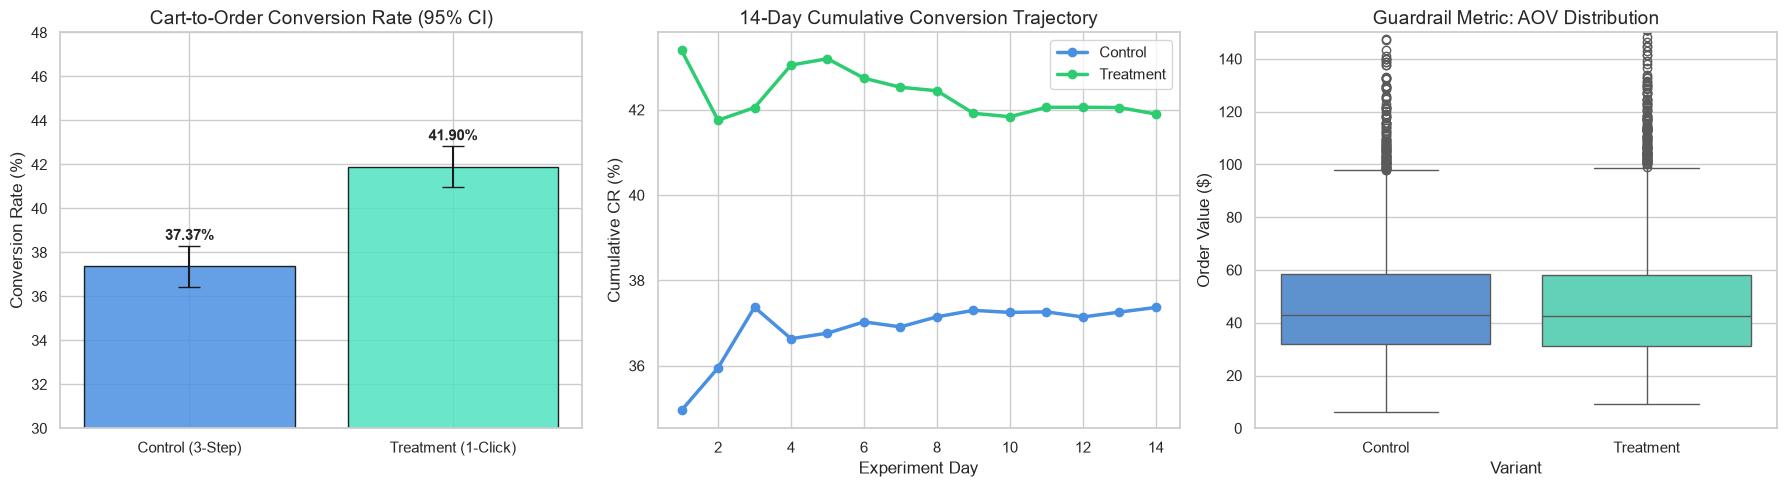

In [7]:
# Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Conversion Rate with Confidence Interval
cr_data = pd.DataFrame({
    "Variant": ["Control (3-Step)", "Treatment (1-Click)"],
    "ConversionRate": [cr_control * 100, cr_treatment * 100],
    "Err": [
        np.sqrt(cr_control * (1 - cr_control) / visitors[1]) * 1.96 * 100,
        np.sqrt(cr_treatment * (1 - cr_treatment) / visitors[0]) * 1.96 * 100
    ]
})

bars = axes[0].bar(
    cr_data["Variant"], cr_data["ConversionRate"],
    yerr=cr_data["Err"], capsize=8,
    color=["#4A90E2", "#50E3C2"], edgecolor="black", alpha=0.85
)
axes[0].set_title("Cart-to-Order Conversion Rate (95% CI)")
axes[0].set_ylabel("Conversion Rate (%)")
axes[0].set_ylim(30, 48)

for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, yval + 1.2, f"{yval:.2f}%", ha="center", fontweight="bold")

# 2. Cumulative Conversion Rate Trajectory
daily_conv = df_ab.groupby(["day", "variant"]).agg(
    daily_visitors=("user_id", "count"),
    daily_orders=("converted", "sum")
).reset_index()

daily_conv["cum_visitors"] = daily_conv.groupby("variant")["daily_visitors"].cumsum()
daily_conv["cum_orders"] = daily_conv.groupby("variant")["daily_orders"].cumsum()
daily_conv["cum_cr"] = (daily_conv["cum_orders"] / daily_conv["cum_visitors"]) * 100

for var, col in zip(["Control", "Treatment"], ["#4A90E2", "#2ECC71"]):
    subset = daily_conv[daily_conv["variant"] == var]
    axes[1].plot(subset["day"], subset["cum_cr"], marker="o", label=var, color=col, linewidth=2.5)

axes[1].set_title("14-Day Cumulative Conversion Trajectory")
axes[1].set_xlabel("Experiment Day")
axes[1].set_ylabel("Cumulative CR (%)")
axes[1].legend()

# 3. Guardrail: AOV Distribution
sns.boxplot(
    data=df_ab[df_ab["converted"] == 1],
    x="variant", y="order_amount",
    palette=["#4A90E2", "#50E3C2"],
    ax=axes[2]
)
axes[2].set_title("Guardrail Metric: AOV Distribution")
axes[2].set_xlabel("Variant")
axes[2].set_ylabel("Order Value ($)")
axes[2].set_ylim(0, 150)

plt.tight_layout()
plt.show()


In [8]:
# Financial ROI & Annualized Business Impact
annual_traffic = 250000  # Annual cart sessions
incremental_orders = annual_traffic * abs_diff
incremental_revenue = incremental_orders * order_val_trt.mean()

print("=== EXECUTIVE BUSINESS IMPACT MODEL ===")
print(f"Annual Cart Checkout Volume:       {annual_traffic:,} visitors")
print(f"Baseline Conversion Rate:          {cr_control * 100:.2f}%")
print(f"Optimized Conversion Rate:         {cr_treatment * 100:.2f}%")
print(f"Incremental Converted Orders:      +{incremental_orders:,.0f} orders/year")
print(f"Average Order Basket Size:         ${order_val_trt.mean():.2f}")
print(f"Projected Incremental Annual GMV:  +${incremental_revenue:,.2f}")
print("\nRECOMMENDATION: Full 100% rollout of 1-Click Guest Checkout approved.")


=== EXECUTIVE BUSINESS IMPACT MODEL ===
Annual Cart Checkout Volume:       250,000 visitors
Baseline Conversion Rate:          37.37%
Optimized Conversion Rate:         41.90%
Incremental Converted Orders:      +11,330 orders/year
Average Order Basket Size:         $47.19
Projected Incremental Annual GMV:  +$534,644.89

RECOMMENDATION: Full 100% rollout of 1-Click Guest Checkout approved.
